# Who Gets the State Grant?
## ДЖТ–география, 2022–2026


## Sources
local originals: `Data/grant_2022.pdf` ... `Data/grant_2026.pdf`.
- [2026](https://www.gov.kz/uploads/2026/8/7/9f5001ceea340a035bacebc8883be8e1_original.50845887.pdf)
- [2025](https://www.gov.kz/uploads/2025/8/7/af433aa904fa3ae1ae0806bd73d3501d_original.34169829.pdf)
- [2024](https://www.gov.kz/uploads/2024/8/3/4d83c2959534c05a1b3b1a29f4828dd9_original.25519389.pdf)
- [2023](https://farabi.university/storage/files/204293661064cde74be1b02162932678_%D0%93%D1%80%D0%B0%D0%BD%D1%82%20%D0%B8%D0%B5%D0%B3%D0%B5%D1%80%D0%BB%D0%B5%D1%80%D1%96%D0%BD%D1%96%D2%A3%20%D1%82%D1%96%D0%B7%D1%96%D0%BC%D1%96%202023.pdf)
- [2022](https://drive.google.com/file/d/1AIfLpFp9XUYJSXaVdfd13Eu3EruAFyOt/view)




## 1. PDF → raw table with no names and id 


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

REEXTRACT = True
if REEXTRACT:
    exec(Path('extract_pdf.py').read_text())

raw = pd.read_csv('raw_no_names.csv', dtype=str).fillna('')
print('Размер сырой таблицы:', raw.shape)
display(raw.head())



2022 done
2023 done
2024 done
2025 done
2026 done
Extraction complete. Clean single-column competition saved.
Размер сырой таблицы: (2757, 5)


,year,group_code,score,university_code,competition
0,2022,B014,133,025,general
1,2022,B014,125,037,general
2,2022,B014,123,196,general
3,2022,B014,121,025,general
4,2022,B014,121,013,general


## 2. Cleaning


In [2]:
import pandas as pd

raw = pd.read_csv('raw_no_names.csv')

# делаем копию таблицы
clean = raw.copy()

# меняем типы данных на целые числа
clean['year'] = clean['year'].astype(int)
clean['score'] = clean['score'].astype(int)

# код вуза делаем красивым (три цифры)
clean['university_code'] = clean['university_code'].astype(str).str.strip().str.zfill(3)

# сохраняем результат
clean.to_csv('cleaned.csv', index=False)
raw1 = pd.read_csv('cleaned.csv', dtype=str).fillna('')
display(raw1.head())

print('Готово! Файл cleaned.csv сохранён')

,year,group_code,score,university_code,competition
0,2022,B014,133,025,general
1,2022,B014,125,037,general
2,2022,B014,123,196,general
3,2022,B014,121,025,general
4,2022,B014,121,013,general


Готово! Файл cleaned.csv сохранён


## 3. Integration


In [4]:
import pandas as pd

# 1. Читаем таблицы и сразу приводим university_code к строковому типу (str)
clean = pd.read_csv('cleaned.csv', dtype={'university_code': str})
universities = pd.read_csv('universities.csv', dtype={'university_code': str})

# Очищаем коды от лишних пробелов и приводим к формату из 3 цифр (например, '25' -> '025')
clean['university_code'] = clean['university_code'].str.strip().str.zfill(3)
universities['university_code'] = universities['university_code'].str.strip().str.zfill(3)

# 2. Соединяем наши данные с названиями вузов
# how='left' сохраняет все строки из clean, даже если для какого-то кода не нашлось названия
integrated = pd.merge(clean, universities, on='university_code', how='left')

# Сохраняем полный файл
integrated.to_csv('integrated_all.csv', index=False)

# 3. Оставляем только общий конкурс
df = integrated[integrated['competition'] == 'general'].copy()
df.to_csv('integrated_general.csv', index=False)

# 4. Проверяем результаты
print('Все выбранные строки:', len(integrated))
print('Общий конкурс:', len(df))
print('Квоты вне анализа:', len(integrated) - len(df))

# Посмотрим, сколько вузов остались без названия (где `university_name` пустой)
missing_names = integrated['university_name'].isna().sum()
if missing_names > 0:
    print(f'⚠️ Внимание: Для {missing_names} строк не нашлось названия вуза в universities.csv!')

# Показываем первые строки
print(df[['year', 'group_code', 'score', 'university_code', 'university_name']].head())

# 5. Делаем сводную таблицу
summary = df.groupby(['year', 'group_code'])['score'].agg(['count', 'min', 'median', 'max']).reset_index()

# Сохраняем сводную таблицу
summary.to_csv('summary.csv', index=False)

# Показываем сводную таблицу
print(summary)

Все выбранные строки: 2757
Общий конкурс: 2077
Квоты вне анализа: 680
   year group_code  score university_code  \
0  2022       B014    133             025   
1  2022       B014    125             037   
2  2022       B014    123             196   
3  2022       B014    121             025   
4  2022       B014    121             013   

                                     university_name  
0  Казахский национальный женский педагогический ...  
1  Международный казахско-турецкий университет им...  
2  Южно-Казахстанский педагогический университет ...  
3  Казахский национальный женский педагогический ...  
4  Евразийский национальный университет имени Л.Н...  
    year group_code  count  min  median  max
0   2022       B014     88   98   104.0  133
1   2022       B015     64  107   111.5  131
2   2022       B032    110   85    89.0  106
3   2022       B034     72   97   104.0  128
4   2023       B014     44  100   106.0  123
5   2023       B015     91  104   109.0  134
6   2023      

In [ ]:

groups = ['B014', 'B015', 'B032', 'B034']

labels = {
    'B014': 'B014 Geography Teachers',
    'B015': 'B015 Humanities Teachers',
    'B032': 'B032 Philosophy',
    'B034': 'B034 History'
}

colors = ['#137C8B', '#C16E38', '#7B5EA7', '#284B63']

Path('plots').mkdir(exist_ok=True)

plt.rcParams.update({
    'font.size': 11,
    'font.family': 'DejaVu Sans'
})


## Вопрос 1. Какая группа получает больше грантов и меняется ли лидер?
**Число:** В 2026 году B014 получила 132 гранта общего конкурса против 110 у B032.

**Ограничение:** Сравнение охватывает только четыре группы и основной общий конкурс, а не весь государственный заказ.

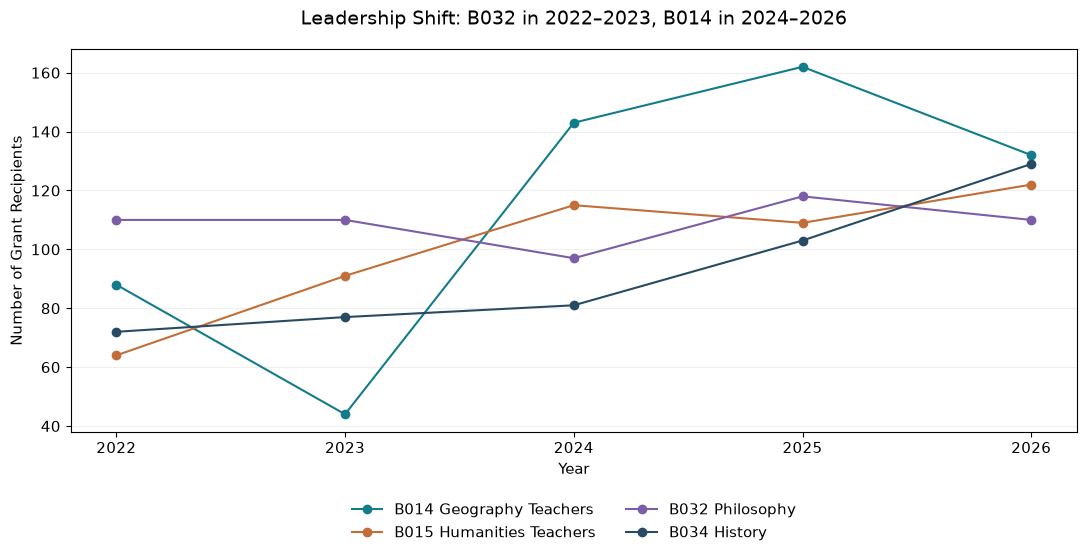

In [29]:
fig, ax = plt.subplots(figsize=(11, 5.8))

for group, color in zip(groups, colors):
    part = summary[summary['group_code'] == group]
    ax.plot(part['year'], part['count'], marker='o',
            label=labels[group], color=color)

ax.set_title('Leadership Shift: B032 in 2022–2023, B014 in 2024–2026',
             fontsize=14, pad=18)

ax.set_xlabel('Year')
ax.set_ylabel('Number of Grant Recipients')
ax.set_xticks([2022, 2023, 2024, 2025, 2026])
ax.grid(axis='y', alpha=0.2)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
          ncol=2, frameon=False)

fig.tight_layout()
fig.savefig('plots/plot_1.png', dpi=180, bbox_inches='tight')
plt.show()

## Вопрос 2. Какая группа имеет самую высокую медиану в разные годы?
**Число:** Медиана B015 выросла с 111,5 в 2022 году до 124 в 2026 году.

**Ограничение:** Это баллы получателей грантов, а не всех абитуриентов; сравнение не измеряет сложность экзамена.

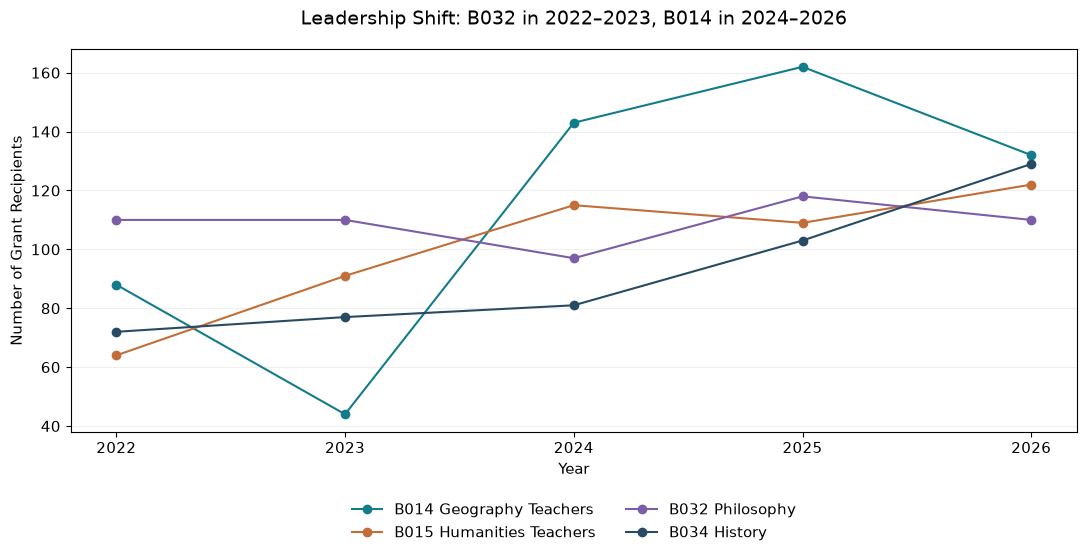

In [22]:
fig, ax = plt.subplots(figsize=(11, 5.8))

for group, color in zip(groups, colors):
    part = summary[summary['group_code'] == group]
    ax.plot(part['year'], part['count'], marker='o',
            label=labels[group], color=color)

ax.set_title('Leadership Shift: B032 in 2022–2023, B014 in 2024–2026',
             fontsize=14, pad=18)

ax.set_xlabel('Year')
ax.set_ylabel('Number of Grant Recipients')
ax.set_xticks([2022, 2023, 2024, 2025, 2026])
ax.grid(axis='y', alpha=0.2)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
          ncol=2, frameon=False)

fig.tight_layout()
fig.savefig('plots/plot_1.png', dpi=180, bbox_inches='tight')
plt.show()

## Вопрос 3. У какой группы сильнее всего изменился минимум с 2022 по 2026?
**Число:** За 2022–2026 годы минимум B032 вырос на 11 баллов, B034 на 10, B014 и B015 на 9.

**Ограничение:** Наблюдаемый минимум не гарантирует поступление: при равных баллах учитываются другие критерии.

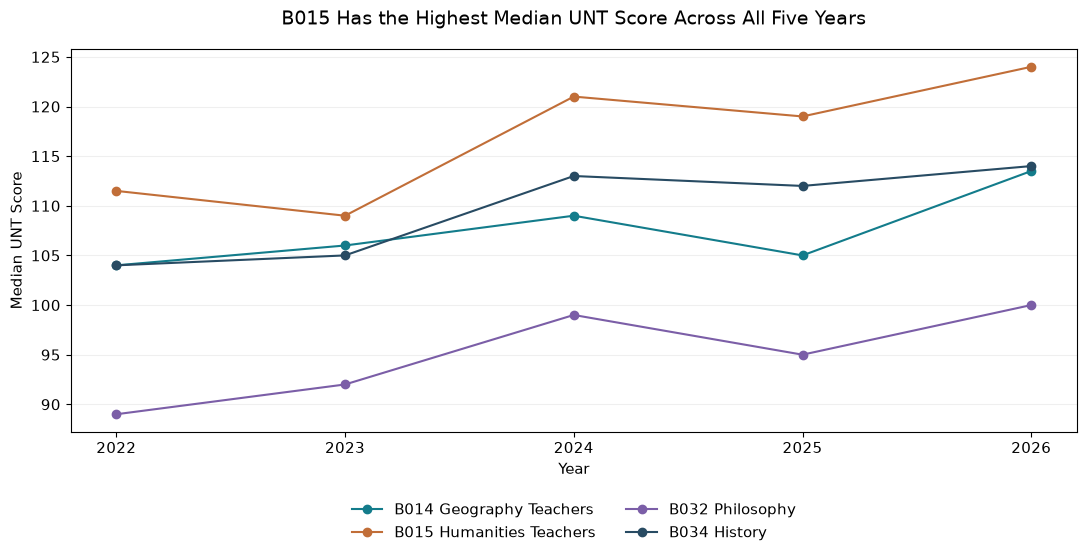

In [23]:
fig, ax = plt.subplots(figsize=(11, 5.8))

for group, color in zip(groups, colors):
    part = summary[summary['group_code'] == group]
    ax.plot(part['year'], part['median'], marker='o',
            label=labels[group], color=color)

ax.set_title('B015 Has the Highest Median UNT Score Across All Five Years',
             fontsize=14, pad=18)

ax.set_xlabel('Year')
ax.set_ylabel('Median UNT Score')
ax.set_xticks([2022, 2023, 2024, 2025, 2026])
ax.grid(axis='y', alpha=0.2)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
          ncol=2, frameon=False)

fig.tight_layout()
fig.savefig('plots/plot_2.png', dpi=180, bbox_inches='tight')
plt.show()

## Вопрос 4. Какие вузы сильнее всего увеличили и сократили число грантов?
**Число:** ЕНУ вырос с 88 до 190 (+102), а КазНУ снизился с 96 до 59 (−37) между 2022 и 2026 годами.

**Ограничение:** Это изменение числа получателей в четырёх группах общего конкурса, а не качества вуза или общего числа его грантов. Показаны три наибольших роста и три наибольших снижения.

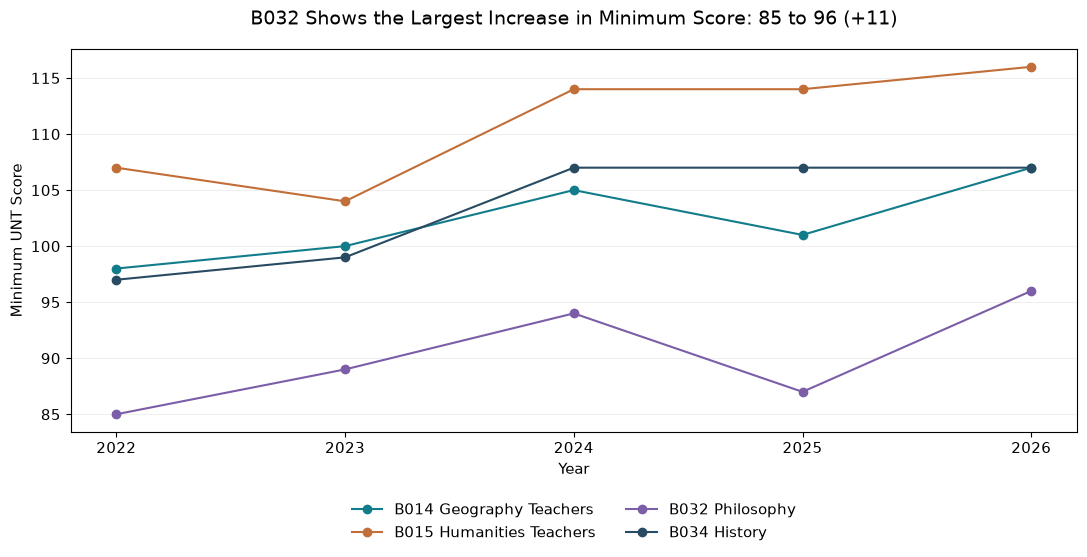

In [24]:
fig, ax = plt.subplots(figsize=(11, 5.8))

for group, color in zip(groups, colors):
    part = summary[summary['group_code'] == group]
    ax.plot(part['year'], part['min'], marker='o',
            label=labels[group], color=color)

ax.set_title('B032 Shows the Largest Increase in Minimum Score: 85 to 96 (+11)',
             fontsize=14, pad=18)

ax.set_xlabel('Year')
ax.set_ylabel('Minimum UNT Score')
ax.set_xticks([2022, 2023, 2024, 2025, 2026])
ax.grid(axis='y', alpha=0.2)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
          ncol=2, frameon=False)

fig.tight_layout()
fig.savefig('plots/plot_3.png', dpi=180, bbox_inches='tight')
plt.show()